# Phase 1: Problem Definition & Dataset Understanding
- **Objective:** Build a Custom CNN to classify the severity of Diabetic Retinopathy into 5 classes (0 to 4).
- **Dataset:** APTOS 2019 Blindness Detection (Gaussian Filtered).

In [72]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import tensorflow as tf
import keras
import os
import cv2
from sklearn.metrics import classification_report , confusion_matrix , ConfusionMatrixDisplay

from keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input

import warnings 
warnings.filterwarnings("ignore")

In [73]:
DATA_PATH = r"/mnt/d/DeepLearning/datasets/Blindness Detection Dataset/gaussian_filtered_images"


BATCH_SIZE = 32
IMG_SIZE = (224, 224)

AUTOTUNE = tf.data.AUTOTUNE

# Phase 2: (EDA) 
- Analyzing class distribution to check for data imbalance.
- Inspecting image dimensions and visually exploring the dataset to identify potential noise or required transformations.

In [74]:
train_csv = pd.read_csv(r"/mnt/d/DeepLearning/datasets/Blindness Detection Dataset/train.csv")

train_csv.head()

,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


diagnosis
0    1805
2     999
1     370
4     295
3     193
Name: count, dtype: int64


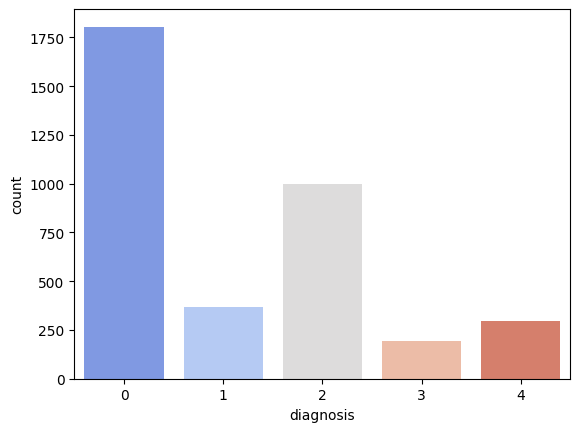

In [75]:
sns.barplot(train_csv["diagnosis"].value_counts(),palette="coolwarm")
print(train_csv['diagnosis'].value_counts())
plt.show()

Shape Of Image 1: (224, 224, 3)
Shape Of Image 2: (224, 224, 3)
Shape Of Image 3: (224, 224, 3)
Shape Of Image 4: (224, 224, 3)
Shape Of Image 5: (224, 224, 3)
Shape Of Image 6: (224, 224, 3)
Shape Of Image 7: (224, 224, 3)
Shape Of Image 8: (224, 224, 3)
Shape Of Image 9: (224, 224, 3)
Shape Of Image 10: (224, 224, 3)


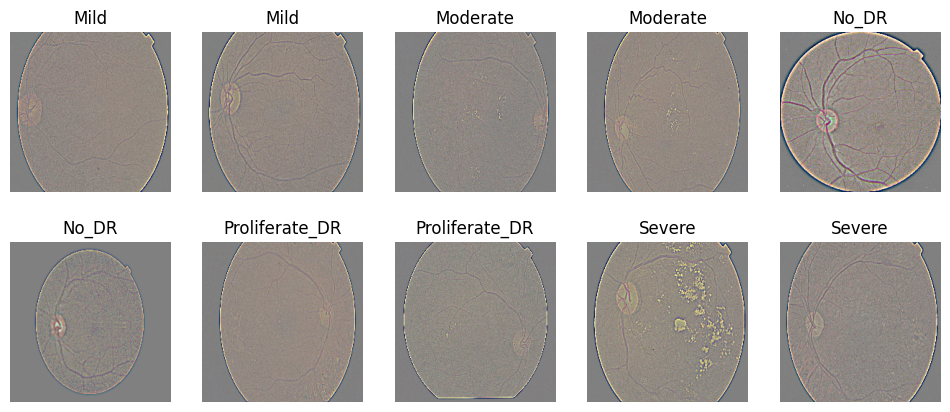

In [76]:
plt.figure(figsize=(12, 5))
count = 1

class_names = []

for folder in os.listdir(DATA_PATH):

    class_names.append(folder)
    folder_path = os.path.join(DATA_PATH, folder)

    for file in os.listdir(folder_path)[:2]:
        img_path = os.path.join(folder_path, file)
        
 
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
        print(f"Shape Of Image {count}: {image.shape}")    

        plt.subplot(2, 5, count)
        plt.imshow(image)
        plt.title(folder)
        plt.axis("off")
        
        count += 1
        
plt.show()

# Phase 3 & 4: Data Splitting & Preprocessing
- Loading images into memory efficiently.
- Splitting the dataset into Training (80%) and Validation (20%).
- Applying `AUTOTUNE` prefetching for hardware optimization.
- Defining a safe Data Augmentation block tailored for medical retinal images.

In [77]:
print("Loading Training Data:")
train_dataset = keras.utils.image_dataset_from_directory(
    DATA_PATH ,
    validation_split = 0.2,
    subset = "training",
    shuffle=True,
    seed=42,
    batch_size = BATCH_SIZE ,
    image_size = IMG_SIZE
)

print("\nLoading Validation Data:")
val_dataset = keras.utils.image_dataset_from_directory(
    DATA_PATH,
    validation_split=0.2,
    subset="validation",
    shuffle=True,
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_dataset.class_names
class_names

Loading Training Data:
Found 3662 files belonging to 5 classes.
Using 2930 files for training.

Loading Validation Data:
Found 3662 files belonging to 5 classes.
Using 732 files for validation.


['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']

In [78]:
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)

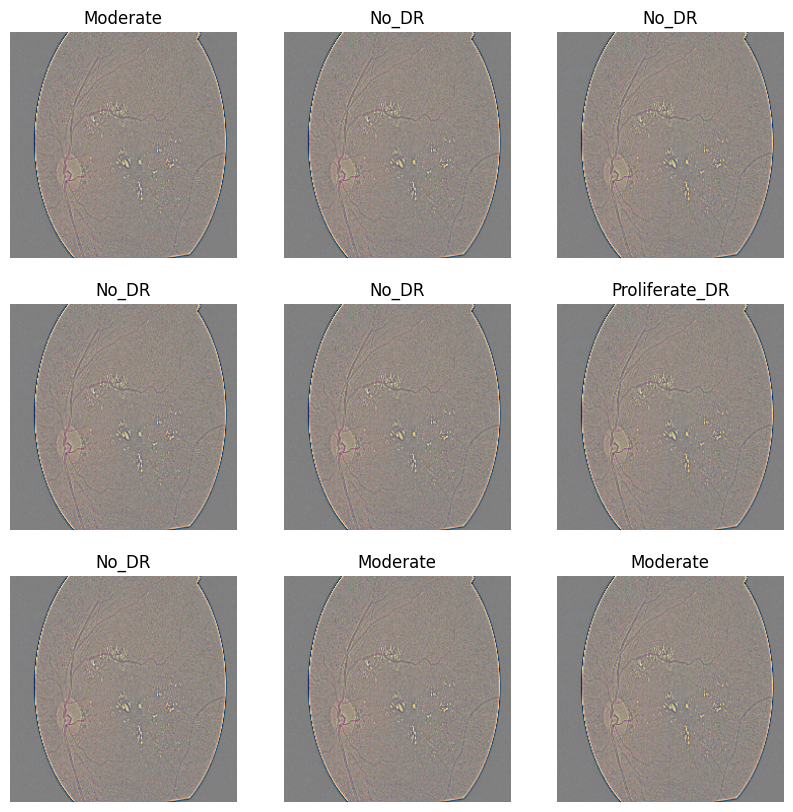

In [79]:
plt.figure(figsize=(10, 10))
for images , labels in train_dataset.take(1):
    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[0].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [80]:
data_augmentation = keras.models.Sequential(
    [
        keras.layers.RandomFlip("horizontal_and_vertical"),
        keras.layers.RandomRotation(0.15,fill_mode="constant", fill_value=0.0),
        keras.layers.RandomZoom(0.15,fill_mode="constant", fill_value=0.0),
        keras.layers.RandomContrast(0.1)
    ], name="data_augmentation_block"
)

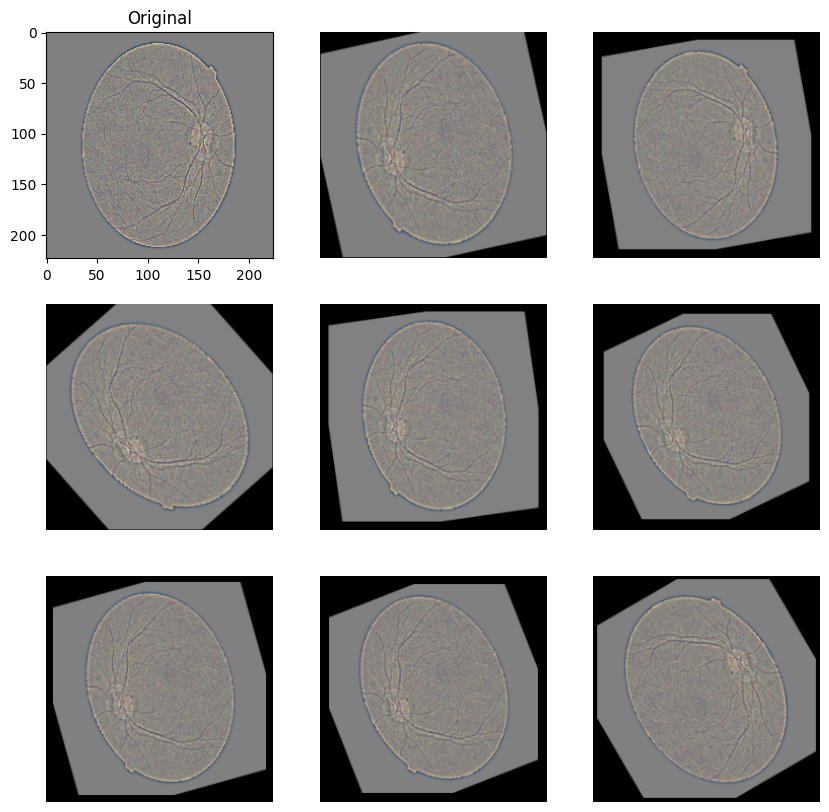

In [81]:
plt.figure(figsize=(10, 10))
for images , labels in train_dataset.take(1):

    plt.subplot(3,3,1)
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title("Original")

    for i in range(8):
        image = data_augmentation(images[:1],training = True)[0]
        plt.subplot(3,3,i+2)
        plt.imshow(image.numpy().astype("uint8"))
        plt.axis("off")

plt.show()

# Phase 5: Baseline CNN Architecture 
- Building a simple Convolutional Neural Network from scratch as a baseline.
- Integrating Data Augmentation and Normalization directly as model layers.

In [82]:
model = keras.models.Sequential([

    data_augmentation,

    keras.layers.Rescaling(1./255,input_shape = (224,224,3)),

    keras.layers.Conv2D(32 , (3,3) , activation="relu"),
    keras.layers.MaxPooling2D((2,2)),

    keras.layers.Conv2D(64 , (3,3) , activation="relu"),
    keras.layers.MaxPooling2D((2,2)),

    keras.layers.Conv2D(128 , (3,3) , activation="relu"),
    keras.layers.MaxPooling2D((2,2)),

    keras.layers.Conv2D(128 , (3,3) , activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    
    keras.layers.Flatten(),

    keras.layers.Dense(128,activation="relu"),
    # keras.layers.Dropout(0.5),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dense(5,activation="softmax")
    
])

In [83]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_block         │ (1, 224, 224, 3)       │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (1, 24, 24, 128)       │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (1, 12, 12, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (1, 18432)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (1, 128)               │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (1, 5)                 │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,608,837 (9.95 MB)

 Trainable params: 2,608,837 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

# Phase 6: Model Compilation & Training 
- Configuring the model with the appropriate loss function, optimizer, and evaluation metrics.
- Setting up callbacks (EarlyStopping, ReduceLROnPlateau).
- Training the baseline model.

In [84]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [85]:
my_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss",
                                  min_delta=0.002,
                                  patience=10,
                                  restore_best_weights=True),

keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                factor=0.5,
                                patience=4)
]

In [86]:
class_counts = {0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}
total_images = sum(class_counts.values())
num_classes = 5


class_weights = {}
for class_id, count in class_counts.items():
    weight = total_images / (num_classes * count)
    class_weights[class_id] = weight

print("Class Weights:", class_weights)

Class Weights: {0: 0.4057617728531856, 1: 1.9794594594594594, 2: 0.7331331331331331, 3: 3.7948186528497407, 4: 2.4827118644067796}


In [87]:
history = model.fit(
    train_dataset,
    batch_size=BATCH_SIZE,
    epochs=100,
    callbacks=my_callbacks,
    validation_data=val_dataset,
    class_weight=class_weights
)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.3304 - loss: 1.9175 - val_accuracy: 0.5000 - val_loss: 1.6033 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.5887 - loss: 1.6391 - val_accuracy: 0.6530 - val_loss: 1.0856 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.6184 - loss: 1.5748 - val_accuracy: 0.6571 - val_loss: 1.0420 - learning_rate: 0.0010
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.6174 - loss: 1.5788 - val_accuracy: 0.6762 - val_loss: 0.9890 - learning_rate: 0.0010
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.6410 - loss: 1.5184 - val_accuracy: 0.6872 - val_loss: 0.9951 - learning_rate: 0.0010
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.6505 - loss: 1.4770 - val_accuracy: 0.6885 - val_loss: 0.9899 - learning_rate: 0.0010
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.6573 - loss: 1.4507 -

# Phase 7: Model Evaluation & Error Analysis 
- Plotting Accuracy and Loss learning curves to check for overfitting or underfitting.
- Generating a Confusion Matrix to analyze the model's performance on each specific severity level.
- Calculating detailed evaluation metrics (Precision, Recall, F1-Score) to assess how well the class weights handled the imbalance.

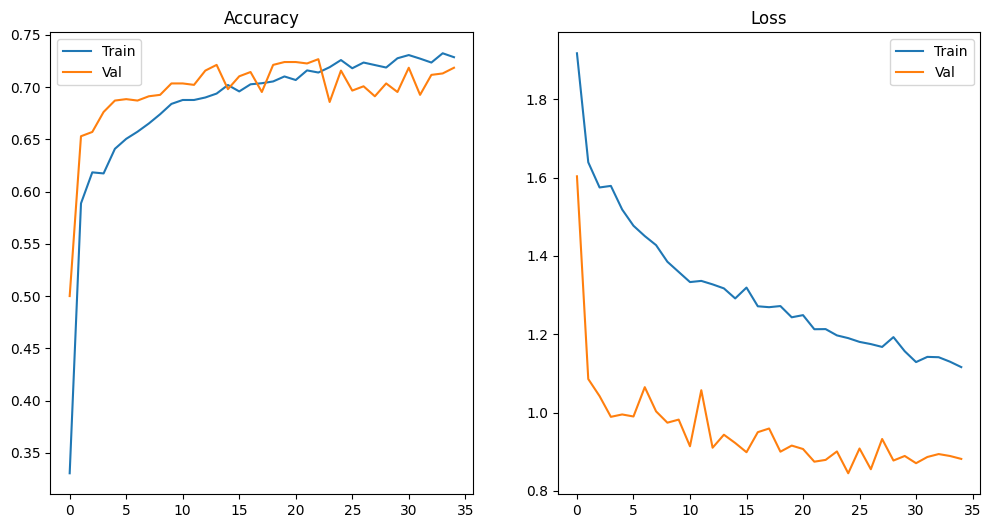

In [88]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"] , label = "Train")
plt.plot(history.history["val_accuracy"], label = "Val")
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"] , label = "Train")
plt.plot(history.history["val_loss"], label = "Val")
plt.title("Loss")
plt.legend()
plt.show()


In [89]:
def return_predictions(model,data):
    y_true = []
    y_pred_probs = []

    for images , labels in data:
        y_true.extend(labels.numpy())
        preds = model.predict(images,verbose=0)
        y_pred_probs.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.argmax(y_pred_probs,axis=1)

    return y_true , y_pred

In [90]:
y_true,y_pred = return_predictions(model,val_dataset)

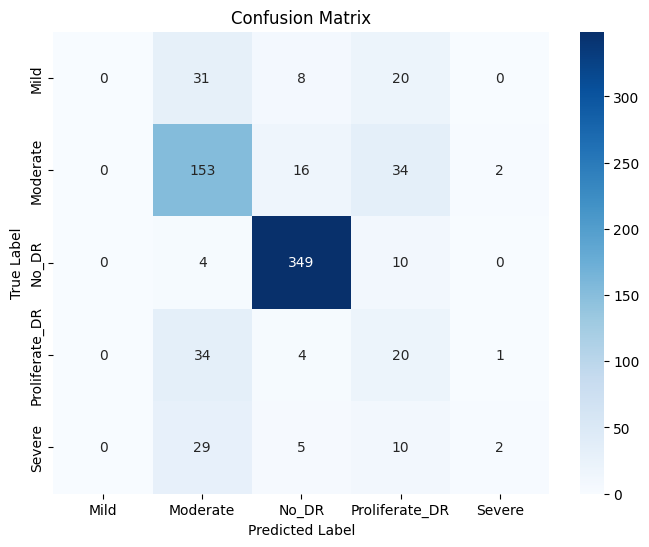

In [91]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [92]:
print("\nClassification Report:\n")
print(classification_report(y_true,y_pred,target_names=class_names))


Classification Report:

                precision    recall  f1-score   support

          Mild       0.00      0.00      0.00        59
      Moderate       0.61      0.75      0.67       205
         No_DR       0.91      0.96      0.94       363
Proliferate_DR       0.21      0.34      0.26        59
        Severe       0.40      0.04      0.08        46

      accuracy                           0.72       732
     macro avg       0.43      0.42      0.39       732
  weighted avg       0.67      0.72      0.68       732



# Phase 9: Transfer Learning (Feature Extraction)
- Using a Pre-trained model (e.g., EfficientNetB0) to extract complex features.
- Freezing the base layers to perform Feature Extraction.
- Adding a custom classification head for the 5 DR classes.

In [ ]:
base_model = EfficientNetB0(weights = "imagenet",include_top=False,input_shape=(224,224,3))

base_model.trainable = False

tl_model1 = keras.models.Sequential([
    data_augmentation,
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(5,activation="softmax")
])

tl_model1.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_block         │ (1, 224, 224, 3)       │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (1, 7, 7, 1280)        │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (1, 1280)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (1, 128)               │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (1, 5)                 │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [94]:
tl_model1.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

tl_history1 = tl_model1.fit(
    train_dataset,
    batch_size=BATCH_SIZE,
    epochs=100,
    callbacks=my_callbacks,
    validation_data=val_dataset,
    class_weight=class_weights
)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 143ms/step - accuracy: 0.6536 - loss: 1.4164 - val_accuracy: 0.7295 - val_loss: 0.9220 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 127ms/step - accuracy: 0.7154 - loss: 1.2192 - val_accuracy: 0.6885 - val_loss: 0.9782 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.7229 - loss: 1.1609 - val_accuracy: 0.7336 - val_loss: 0.8138 - learning_rate: 0.0010
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 127ms/step - accuracy: 0.7263 - loss: 1.1290 - val_accuracy: 0.7158 - val_loss: 0.8471 - learning_rate: 0.0010
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.7396 - loss: 1.0868 - val_accuracy: 0.7186 - val_loss: 0.8543 - learning_rate: 0.0010
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 132ms/step - accuracy: 0.7386 - loss: 1.0998 - val_accuracy: 0.5943 - val_loss: 1.0218 - learning_rate: 0.0010
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 127ms/step - accuracy: 0.7372 - l

# Phase 10: Fine-Tuning & Gradual Unfreezing
- Unfreezing the top layers of the pre-trained `EfficientNetB0` model.
- Keeping `BatchNormalization` layers frozen to maintain stable training.
- Re-compiling the model with a very low Learning Rate (e.g., 1e-5) to prevent catastrophic forgetting.
- Training the model to specialize in detecting subtle diabetic retinopathy lesions.

In [95]:
def set_trainable_layers(base_model, num_unfrozen):
    """Unfreeze only the last num_unfrozen layers of the base. Keep BatchNorm frozen."""
    if num_unfrozen <= 0:
        base_model.trainable = False
        return

    base_model.trainable = True                          
    for layer in base_model.layers[:-num_unfrozen]:      
        layer.trainable = False
    for layer in base_model.layers[-num_unfrozen:]:    
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

In [96]:
set_trainable_layers(base_model,30)

tl_model1.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

tl_history1 = tl_model1.fit(
    train_dataset,
    batch_size=BATCH_SIZE,
    epochs=100,
    callbacks=my_callbacks,
    validation_data=val_dataset,
    class_weight=class_weights
)

Epoch 1/100


E0000 00:00:1791722539.710299   14640 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_5_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 155ms/step - accuracy: 0.7365 - loss: 1.1087 - val_accuracy: 0.7363 - val_loss: 0.8105 - learning_rate: 1.0000e-05
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.7416 - loss: 1.0846 - val_accuracy: 0.7391 - val_loss: 0.8386 - learning_rate: 1.0000e-05
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 143ms/step - accuracy: 0.7454 - loss: 1.0634 - val_accuracy: 0.7240 - val_loss: 0.8725 - learning_rate: 1.0000e-05
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 138ms/step - accuracy: 0.7410 - loss: 1.0741 - val_accuracy: 0.7377 - val_loss: 0.8435 - learning_rate: 1.0000e-05
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 138ms/step - accuracy: 0.7485 - loss: 1.0672 - val_accuracy: 0.7199 - val_loss: 0.8819 - learning_rate: 1.0000e-05
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 139ms/step - accuracy: 0.7468 - loss: 1.0500 - val_accuracy: 0.7063 - val_loss: 0.9001 - learning_rate: 5.0000e-06
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy

In [97]:
y_true , y_pred = return_predictions(tl_model1,val_dataset)

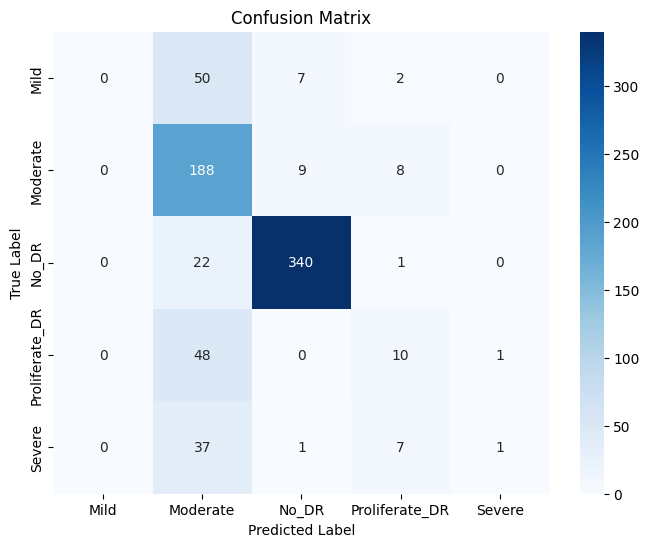

In [98]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [99]:
print("\nClassification Report:\n")
print(classification_report(y_true,y_pred,target_names=class_names))


Classification Report:

                precision    recall  f1-score   support

          Mild       0.00      0.00      0.00        59
      Moderate       0.54      0.92      0.68       205
         No_DR       0.95      0.94      0.94       363
Proliferate_DR       0.36      0.17      0.23        59
        Severe       0.50      0.02      0.04        46

      accuracy                           0.74       732
     macro avg       0.47      0.41      0.38       732
  weighted avg       0.69      0.74      0.68       732



# Phase 11: Model Experimentation (ResNet50V2) 
- Experimenting with `ResNet50V2` to address the misclassification issues in the challenging 'Moderate' class.
- Applying model-specific data preprocessing (`preprocess_input` to scale pixels to `[-1, 1]`).
- Phase A: Feature Extraction (Freezing base weights and training the custom classification head).
- Phase B: Fine-Tuning (Unfreezing top layers and training with a very low learning rate to optimize weights specifically for DR detection).

In [100]:
resnet_base = ResNet50V2(weights="imagenet",include_top=False,input_shape=(224,224,3))

resnet_base.trainable = False

tl_model2 = keras.models.Sequential([
    data_augmentation,

    keras.layers.Lambda(lambda x : preprocess_input(x)),

    resnet_base,

    keras.layers.GlobalAveragePooling2D(),

    keras.layers.Dense(128,activation="relu"),

    keras.layers.Dropout(0.3),
    
    keras.layers.Dense(64,activation="relu"),

    keras.layers.Dense(5,activation="softmax")
])

In [101]:
tl_model2.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_block         │ (1, 224, 224, 3)       │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (1, 7, 7, 2048)        │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (1, 2048)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (1, 128)               │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (1, 5)                 │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,835,653 (90.93 MB)

 Trainable params: 270,853 (1.03 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [102]:
tl_model2.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

tl_history2 = tl_model2.fit(
            train_dataset,
            batch_size=BATCH_SIZE,
            epochs=100,
            callbacks=my_callbacks,
            validation_data=val_dataset,
            class_weight=class_weights,
)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 163ms/step - accuracy: 0.6133 - loss: 1.6092 - val_accuracy: 0.6844 - val_loss: 0.9097 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 151ms/step - accuracy: 0.6918 - loss: 1.3354 - val_accuracy: 0.7213 - val_loss: 0.8903 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 150ms/step - accuracy: 0.6945 - loss: 1.2902 - val_accuracy: 0.7377 - val_loss: 0.8122 - learning_rate: 0.0010
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 150ms/step - accuracy: 0.7154 - loss: 1.2234 - val_accuracy: 0.7227 - val_loss: 0.8775 - learning_rate: 0.0010
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.7239 - loss: 1.1742 - val_accuracy: 0.7158 - val_loss: 0.8773 - learning_rate: 5.0000e-04
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.7229 - loss: 1.1893 - val_accuracy: 0.7090 - val_loss: 0.8604 - learning_rate: 5.0000e-04
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 152ms/step - accuracy: 0.

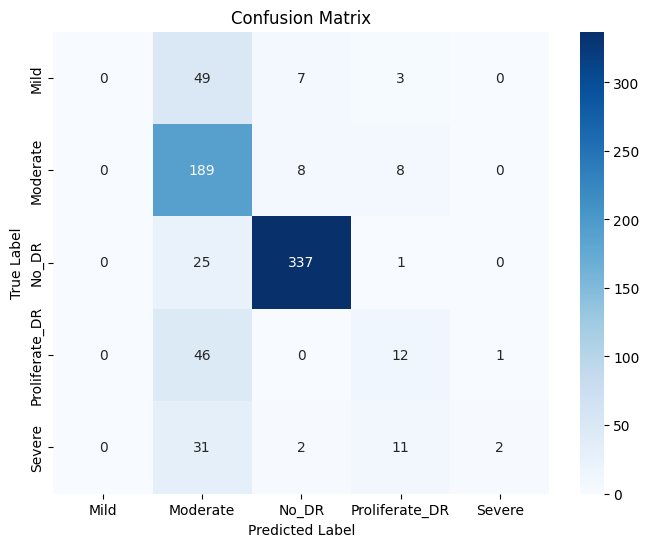


Classification Report:

                precision    recall  f1-score   support

          Mild       0.00      0.00      0.00        59
      Moderate       0.56      0.92      0.69       205
         No_DR       0.95      0.93      0.94       363
Proliferate_DR       0.34      0.20      0.26        59
        Severe       0.67      0.04      0.08        46

      accuracy                           0.74       732
     macro avg       0.50      0.42      0.39       732
  weighted avg       0.70      0.74      0.69       732



In [103]:
y_true , y_pred = return_predictions(tl_model2,val_dataset)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true,y_pred,target_names=class_names))

In [104]:
set_trainable_layers(resnet_base,30)

tl_model2.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

print(tl_model2.summary())
tl_history2 = tl_model2.fit(
            train_dataset,
            batch_size=BATCH_SIZE,
            epochs=100,
            callbacks=my_callbacks,
            validation_data=val_dataset,
            class_weight=class_weights,
)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_block         │ (1, 224, 224, 3)       │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (1, 7, 7, 2048)        │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (1, 2048)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (1, 128)               │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (1, 5)                 │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,835,653 (90.93 MB)

 Trainable params: 14,696,965 (56.06 MB)

 Non-trainable params: 9,138,688 (34.86 MB)

None
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 205ms/step - accuracy: 0.7451 - loss: 1.0663 - val_accuracy: 0.6762 - val_loss: 0.9717 - learning_rate: 1.0000e-05
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 195ms/step - accuracy: 0.7471 - loss: 1.0600 - val_accuracy: 0.7281 - val_loss: 0.8210 - learning_rate: 1.0000e-05
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 193ms/step - accuracy: 0.7491 - loss: 1.0179 - val_accuracy: 0.7240 - val_loss: 0.7837 - learning_rate: 1.0000e-05
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 193ms/step - accuracy: 0.7505 - loss: 1.0138 - val_accuracy: 0.7158 - val_loss: 0.8235 - learning_rate: 1.0000e-05
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 194ms/step - accuracy: 0.7539 - loss: 0.9913 - val_accuracy: 0.7445 - val_loss: 0.7652 - learning_rate: 5.0000e-06
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 196ms/step - accuracy: 0.7522 - loss: 0.9784 - val_accuracy: 0.7541 - val_loss: 0.7364 - learning_rate: 5.0000e-06
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 194m

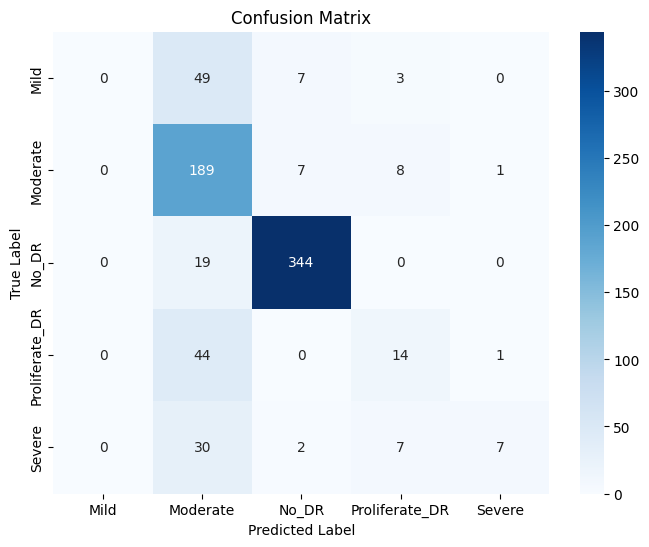


Classification Report:

                precision    recall  f1-score   support

          Mild       0.00      0.00      0.00        59
      Moderate       0.57      0.92      0.71       205
         No_DR       0.96      0.95      0.95       363
Proliferate_DR       0.44      0.24      0.31        59
        Severe       0.78      0.15      0.25        46

      accuracy                           0.76       732
     macro avg       0.55      0.45      0.44       732
  weighted avg       0.72      0.76      0.71       732



In [105]:
y_true , y_pred = return_predictions(tl_model2,val_dataset)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true,y_pred,target_names=class_names))

# Phase 12: Model Saving & Deployment Preparation 
- Saving the final trained `resnet50v2` model to disk.
- Preparing the saved model to be integrated into an interactive web application using Streamlit.

In [108]:

model_save_path = 'resnet50v2_model.h5'

tl_model2.save(model_save_path)

print("Model saved successfully")

Model saved successfully
